In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import datetime
import os
import glob

BASE_PATH = r"/home/ashutosh-tiwari/Desktop/CausalProject" 

PEAK_HOURS = [8, 9, 10, 11, 17, 18, 19, 20]

In [39]:
def load_pollution_data(peak_hours, treated_list, controlled_list, years_to_load, base_path=BASE_PATH):
    """
    Loads, cleans, and filters pollution data for a specific list of stations 
    around a given intervention date.
    
    Parameters:
    -----------
    peak_hours : list
        List of integers representing hours to keep (e.g., [8, 9, 10]).
    intervention_date : datetime.datetime
        The date of the metro opening/intervention.
    window_days : int
        Number of days before and after the intervention to include.
    stations_list : list
        List of strings containing station names to search for.
    base_path : str
        The root directory containing station data folders.
        
    Returns:
    --------
    pd.DataFrame
        Combined dataframe of all loaded stations. Returns None if no data found.
    """

    stations_list = treated_list + controlled_list
    years_to_load = sorted(years_to_load)
    y0, y1, y2 = years_to_load
    
    print(f"\n{'='*100}")
    print(f"PROCESSING DATA")
    print(f"{'='*100}")
    print(f"{'STATION NAME':<25} | {'ROWS':<8} | {'MISSING PM2.5 (N/%)':<22} | {'MISSING PM10 (N/%)':<22}")
    print(f"{'='*100}")

    all_data = []

    for station in stations_list:
        for year in years_to_load:
            search_pattern = os.path.join(base_path, f"*{station}*", f"*{year}*.csv")
            files = glob.glob(search_pattern)
            
            if not files:
                search_pattern_loose = os.path.join(base_path, "**", f"*{station}*{year}*.csv")
                files = glob.glob(search_pattern_loose, recursive=True)

            if not files:
                print(f"{station:<25} | {'NO FILE':<8} | {'-':<22} | {'-':<22}")
                continue
            
            file_path = files[0]
            
            try:
                df = pd.read_csv(file_path)
                
                df.columns = [c.strip() for c in df.columns]
                col_map = {}
                for col in df.columns:
                    if 'Timestamp' in col: col_map[col] = 'TimeStamp'
                    elif 'PM2.5' in col: col_map[col] = 'PM2.5'
                    elif 'PM10' in col: col_map[col] = 'PM10'
                
                df = df.rename(columns=col_map)
                
                if 'TimeStamp' not in df.columns or 'PM2.5' not in df.columns or 'PM10' not in df.columns:
                    print(f"{station:<25} | {'BAD COLS':<8} | {'-':<22} | {'-':<22}")
                    continue

                df['TimeStamp'] = pd.to_datetime(df['TimeStamp'], errors='coerce')
                
                df_window = df.copy()

                df_window['Hour'] = df_window['TimeStamp'].dt.hour
                df_peak = df_window[df_window['Hour'].isin(peak_hours)].copy()
                
                df_peak['StationName'] = station
                df_peak['D'] = 1 if station in treated_list else 0

                # ----- NEW: define 6 sub-periods -----
                year = df_peak['TimeStamp'].dt.year
                month = df_peak['TimeStamp'].dt.month

                # period index 1..6, 0 = “none” (just in case)
                conditions = [
                    (year == y0) & month.between(1, 6),   # P1
                    (year == y0) & month.between(7, 12),  # P2
                    (year == y1) & month.between(1, 6),   # P3
                    (year == y1) & month.between(7, 12),  # P4
                    (year == y2) & month.between(1, 6),   # P5
                    (year == y2) & month.between(7, 12),  # P6
                ]
                choices = [1, 2, 3, 4, 5, 6]

                period = np.select(conditions, choices, default=0)

                for j in range(1, 7):
                    df_peak[f'P{j}'] = (period == j).astype(int)
                # ----- END NEW -----
                
                final_df = df_peak[['TimeStamp', 'PM2.5', 'PM10', 'StationName', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']]
                
                total_rows = len(final_df)
                missing_pm25 = final_df['PM2.5'].isna().sum()
                missing_pm10 = final_df['PM10'].isna().sum()
                
                if total_rows > 0:
                    pm25_pct = (missing_pm25 / total_rows) * 100
                    pm10_pct = (missing_pm10 / total_rows) * 100
                else:
                    pm25_pct = 0
                    pm10_pct = 0
                
                pm25_str = f"{missing_pm25} ({pm25_pct:.1f}%)"
                pm10_str = f"{missing_pm10} ({pm10_pct:.1f}%)"
                
                print(f"{station:<25} | {total_rows:<8} | {pm25_str:<22} | {pm10_str:<22}")
                
                all_data.append(final_df)
                
            except Exception as e:
                print(f"Error processing {station}: {e}")

    print(f"{'='*100}")

    if all_data:
        combined_df = pd.concat(all_data, ignore_index=True)
        return combined_df
    else:
        return None

In [53]:

def run_single_stage_ols(df, pollutant_col, years_to_load, intervention_date):
    """
    Runs the specific OLS regression for the Single Stage DiD setup.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The dataframe containing 'TimeStamp', 'D', 'P1'...'P6', and pollutant columns.
    pollutant_col : str
        The name of the dependent variable (e.g., 'PM2.5' or 'PM10').
    years_to_load : list
        List of 3 years [y0, y1, y2] loaded.
    intervention_date : datetime.datetime
        The date of the metro opening.
        
    Returns:
    --------
    model : statsmodels.regression.linear_model.RegressionResultsWrapper
        The fitted OLS model.
    """
    
    print(f"\n{'='*60}")
    print(f"RUNNING SINGLE STAGE OLS FOR: {pollutant_col}")
    print(f"{'='*60}")
    
    years = sorted(years_to_load)
    int_year = intervention_date.year
    int_month = intervention_date.month
    
    intervention_period_idx = -1
    
    if int_year == years[0]:
        intervention_period_idx = 1 if int_month <= 6 else 2
    elif int_year == years[1]:
        intervention_period_idx = 3 if int_month <= 6 else 4
    elif int_year == years[2]:
        intervention_period_idx = 5 if int_month <= 6 else 6
        
    reference_period_idx = intervention_period_idx - 1
    
    if reference_period_idx < 1:
        print("Warning: Intervention is in the first period. Cannot drop a pre-period.")
        reference_period_idx = 1
        
    print(f"Intervention Date: {intervention_date.date()}")
    print(f"Intervention falls in Period: P{intervention_period_idx}")
    print(f"Dropping Reference Period (P0 equivalent): P{reference_period_idx}")
    
    time_terms = []
    interaction_terms = []
    
    for j in range(1, 7):
        if j == reference_period_idx:
            continue
            
        p_col = f"P{j}"
        time_terms.append(p_col)
        interaction_terms.append(f"{p_col}:D")
        
    formula = f"{pollutant_col} ~ D + " + " + ".join(time_terms) + " + " + " + ".join(interaction_terms)
    
    print(f"Regression Formula: \n{formula}")
    
    try:
        model = smf.ols(formula, data=df).fit(cov_type='HC3')
        print("\n" + "-"*30)
        print("REGRESSION RESULTS")
        print("-"*30)
        print(model.summary())
        
        # ========= ✅ NEW: EVENT-STUDY PLOT OF INTERACTION TERMS =========
        coef_list = []
        se_list = []
        rel_time = []

        for j in range(1, 7):
            if j == reference_period_idx:
                continue
            term = f"P{j}:D"
            if term not in model.params.index:
                continue

            coef = model.params[term]
            se   = model.bse[term]
            # event time: 0 = intervention period
            t_rel = j - intervention_period_idx + 1

            coef_list.append(coef)
            se_list.append(se)
            rel_time.append(t_rel)

        coef_arr = np.array(coef_list)
        se_arr   = np.array(se_list)
        t_arr    = np.array(rel_time)

        # sort by event time
        order = np.argsort(t_arr)
        coef_arr = coef_arr[order]
        se_arr   = se_arr[order]
        t_arr    = t_arr[order]

        # 95% CI
        z = 1.96
        ci = z * se_arr

        fig, ax = plt.subplots()
        ax.errorbar(t_arr, coef_arr, yerr=ci, fmt='o', capsize=4)

        ax.axhline(0, linewidth=1)          # horizontal 0 line
        ax.axvline(0, linewidth=1)          # intervention at 0

        ax.set_xlabel("t (event time)")
        ax.set_ylabel("DiD coefficient")
        ax.set_title(f"Event-study: {pollutant_col}")
        ax.set_xticks(t_arr)

        plt.show()
        # ========= ✅ END NEW PART =========

    except Exception as e:
        print(f"Error running OLS: {e}")


PROCESSING DATA
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 2920     | 1598 (54.7%)           | 1831 (62.7%)          
Punjabi Bagh              | 2920     | 115 (3.9%)             | 119 (4.1%)            
Punjabi Bagh              | 2920     | 97 (3.3%)              | 86 (2.9%)             
Wazirpur                  | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Wazirpur                  | 2920     | 302 (10.3%)            | 381 (13.0%)           
Wazirpur                  | 2920     | 42 (1.4%)              | 112 (3.8%)            
Ashok Vihar               | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Ashok Vihar               | 2920     | 297 (10.2%)            | 312 (10.7%)           
Ashok Vihar               | 2920     | 28 (1.0%)              | 32 (1.1%)             
JahangirPuri              | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
JahangirPuri              

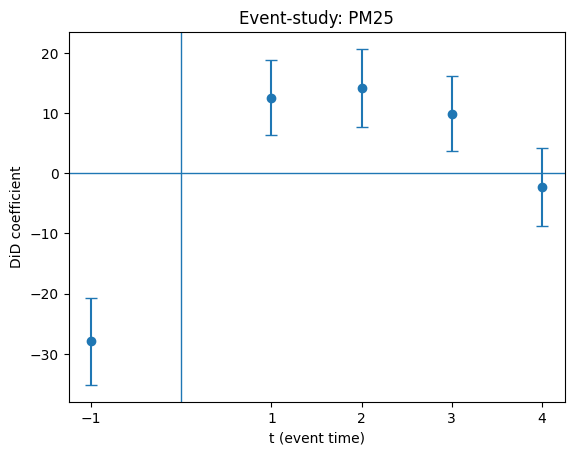


RUNNING SINGLE STAGE OLS FOR: PM10
Intervention Date: 2018-03-14
Intervention falls in Period: P3
Dropping Reference Period (P0 equivalent): P2
Regression Formula: 
PM10 ~ D + P1 + P3 + P4 + P5 + P6 + P1:D + P3:D + P4:D + P5:D + P6:D

------------------------------
REGRESSION RESULTS
------------------------------
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     189.3
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        15:19:26   Log-Likelihood:            -6.8867e+05
No. Observations:              105974   AIC:                         1.377e+06
Df Residuals:                  105962   BIC:                         1.377e+06
Df Model:                          11              

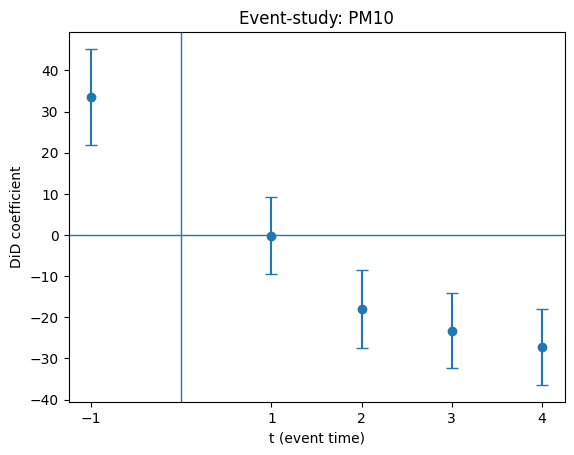

In [54]:
treated_list = [
    "Punjabi Bagh", "Wazirpur", "Ashok Vihar",
    "JahangirPuri", "Burari Crossing", "Shadipur",
    "R K Puram", "Pusa", "North Campus"
]

controlled_list = [
    "Najafgarh", "Narela", "Bawana", "Mundka", 
    "Rohini", "DTU", "Aya Nagar", "Dwarka Sector 8",
    "Dr. Karni Singh Shooting Range", "IGI Airport (T3)",
    "Mandir Marg", "NSIT Dwarka", "Alipur"
]

INTERVENTION_DATE = datetime.datetime(2018, 3, 14)

years_to_load = [2017, 2018, 2019]

df = load_pollution_data(PEAK_HOURS, treated_list, controlled_list, years_to_load, base_path=BASE_PATH)

df_pm25 = df[['TimeStamp', 'StationName', 'PM2.5', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']].copy()
df_pm25 = df_pm25.dropna(subset=['PM2.5'])
df_pm25 = df_pm25.rename(columns={'PM2.5': 'PM25'})
run_single_stage_ols(df_pm25, 'PM25', years_to_load, INTERVENTION_DATE)
        
df_pm10 = df[['TimeStamp', 'StationName', 'PM10', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']].copy()
df_pm10 = df_pm10.dropna(subset=['PM10'])
run_single_stage_ols(df_pm10, 'PM10', years_to_load, INTERVENTION_DATE)



LOADING DATA FOR STAGE 2...

PROCESSING DATA
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Nehru Nagar               | 2920     | 311 (10.7%)            | 321 (11.0%)           
Nehru Nagar               | 2920     | 31 (1.1%)              | 96 (3.3%)             
JawaharLal Nehru Stadium  | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
JawaharLal Nehru Stadium  | 2920     | 382 (13.1%)            | 372 (12.7%)           
JawaharLal Nehru Stadium  | 2920     | 62 (2.1%)              | 105 (3.6%)            
Sirifort                  | 2920     | 637 (21.8%)            | 2920 (100.0%)         
Sirifort                  | 2920     | 375 (12.8%)            | 988 (33.8%)           
Sirifort                  | 2920     | 123 (4.2%)             | 123 (4.2%)            
Lodhi Garden              | 2920     | 2920 (100.0%)          | 2920 (100.0%)       

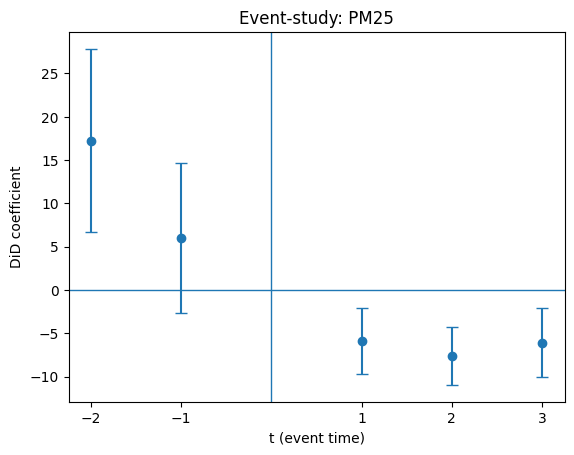


STAGE 2: PM10 ANALYSIS

RUNNING SINGLE STAGE OLS FOR: PM10
Intervention Date: 2018-08-06
Intervention falls in Period: P4
Dropping Reference Period (P0 equivalent): P3
Regression Formula: 
PM10 ~ D + P1 + P2 + P4 + P5 + P6 + P1:D + P2:D + P4:D + P5:D + P6:D

------------------------------
REGRESSION RESULTS
------------------------------
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     129.2
Date:                Wed, 26 Nov 2025   Prob (F-statistic):          2.20e-269
Time:                        15:26:53   Log-Likelihood:            -5.8307e+05
No. Observations:               89845   AIC:                         1.166e+06
Df Residuals:                   89834   BIC:                         1.166e+06
Df Model:                  

/home/ashutosh-tiwari/Desktop/CausalProject/venv/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 11, but rank is 10
  warnings.warn('covariance of constraints does not have full '


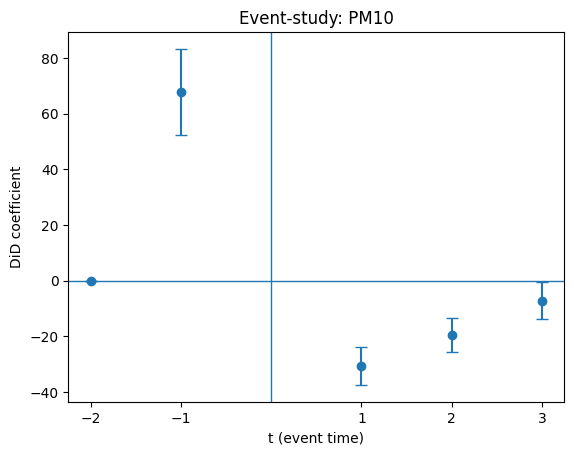

In [57]:

# 1. Define Groups
stage2_treated = [
    "Nehru Nagar", "JawaharLal Nehru Stadium",
    "Sirifort", "Lodhi Garden",
    "Sri Aurbindo Marg", "CRRI Mathura Road",
    "Major Dhyan Chand National Stadium"
]

# Control Group: Use only NEVER treated stations (Clean Controls)
# Exclude Stage 1 stations as they are already treated
stage2_controlled = [
    "Najafgarh", "Narela", "Bawana", "Mundka", 
    "Rohini", "DTU", "Aya Nagar", "Dwarka Sector 8",
    "Dr. Karni Singh Shooting Range", "IGI Airport (T3)",
    "Mandir Marg", "NSIT Dwarka", "Alipur"
]

# 2. Define Parameters
INTERVENTION_DATE_S2 = datetime.datetime(2018, 8, 6)
YEARS_TO_LOAD = [2017, 2018, 2019]

# ==========================================
# EXECUTION
# ==========================================

# 1. Load Data
print("\nLOADING DATA FOR STAGE 2...")
df_s2 = load_pollution_data(PEAK_HOURS, stage2_treated, stage2_controlled, YEARS_TO_LOAD, base_path=BASE_PATH)

if df_s2 is not None:
    # 2. Prepare PM2.5 Data
    # Ensure all P1-P6 columns are present (handled by load_pollution_data)
    cols = ['TimeStamp', 'StationName', 'PM2.5', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm25_s2 = df_s2[cols].copy()
    
    # Clean PM2.5
    # Force numeric conversion to handle any non-numeric strings
    df_pm25_s2['PM2.5'] = pd.to_numeric(df_pm25_s2['PM2.5'], errors='coerce')
    df_pm25_s2 = df_pm25_s2.dropna(subset=['PM2.5'])
    df_pm25_s2 = df_pm25_s2.rename(columns={'PM2.5': 'PM25'})
    
    # Run OLS for PM2.5
    print("\n" + "="*30)
    print("STAGE 2: PM2.5 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm25_s2, 'PM25', YEARS_TO_LOAD, INTERVENTION_DATE_S2)
    
    # 3. Prepare PM10 Data
    cols = ['TimeStamp', 'StationName', 'PM10', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm10_s2 = df_s2[cols].copy()
    
    # Clean PM10
    df_pm10_s2['PM10'] = pd.to_numeric(df_pm10_s2['PM10'], errors='coerce')
    df_pm10_s2 = df_pm10_s2.dropna(subset=['PM10'])
    
    # Run OLS for PM10
    print("\n" + "="*30)
    print("STAGE 2: PM10 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm10_s2, 'PM10', YEARS_TO_LOAD, INTERVENTION_DATE_S2)

else:
    print("Failed to load data for Stage 2.")


LOADING DATA FOR STAGE 3...

PROCESSING DATA
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 2920     | 1297 (44.4%)           | 1688 (57.8%)          
Anand Vihar               | 2920     | 570 (19.5%)            | 624 (21.4%)           
Anand Vihar               | 2920     | 112 (3.8%)             | 181 (6.2%)            
Patparganj                | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Patparganj                | 2920     | 307 (10.5%)            | 343 (11.7%)           
Patparganj                | 2920     | 48 (1.6%)              | 123 (4.2%)            
Vivek Vihar               | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Vivek Vihar               | 2920     | 383 (13.1%)            | 396 (13.6%)           
Vivek Vihar               | 2920     | 74 (2.5%)              | 158 (5.4%)            
IHBAS                     | 2920     | 998 (34.2%)            | 2920 (100.0%)       

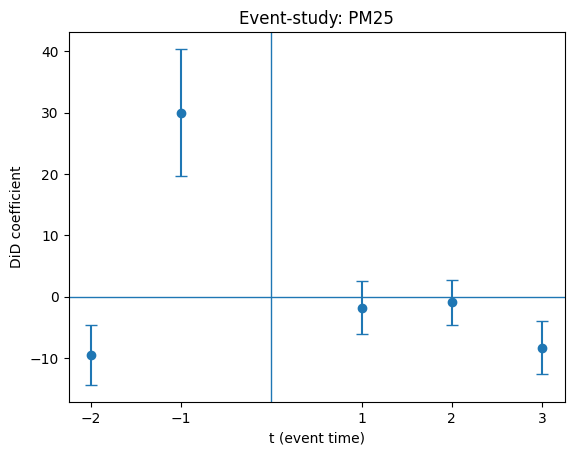


STAGE 3: PM10 ANALYSIS

RUNNING SINGLE STAGE OLS FOR: PM10
Intervention Date: 2018-10-31
Intervention falls in Period: P4
Dropping Reference Period (P0 equivalent): P3
Regression Formula: 
PM10 ~ D + P1 + P2 + P4 + P5 + P6 + P1:D + P2:D + P4:D + P5:D + P6:D

------------------------------
REGRESSION RESULTS
------------------------------
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     301.0
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        15:29:21   Log-Likelihood:            -4.8785e+05
No. Observations:               75206   AIC:                         9.757e+05
Df Residuals:                   75194   BIC:                         9.758e+05
Df Model:                  

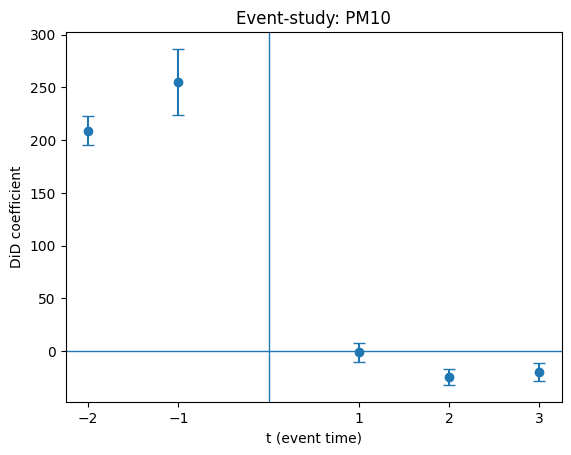

In [58]:
import pandas as pd
import datetime
# Assuming load_pollution_data and run_single_stage_ols are already defined

# ==========================================
# CONFIGURATION FOR STAGE 3
# ==========================================

# 1. Define Groups
stage3_treated = [
    "Anand Vihar", "Patparganj", "Vivek Vihar",
    "IHBAS", "Chandi Chowk"
]

# Control Group (Same as before - Never Treated)
stage3_controlled = [
    "Najafgarh", "Narela", "Bawana", "Mundka", 
    "Rohini", "DTU", "Aya Nagar", "Dwarka Sector 8",
    "Dr. Karni Singh Shooting Range", "IGI Airport (T3)",
    "Mandir Marg", "NSIT Dwarka", "Alipur"
]

# 2. Define Parameters
INTERVENTION_DATE_S3 = datetime.datetime(2018, 10, 31)
YEARS_TO_LOAD = [2017, 2018, 2019]
PEAK_HOURS = [8, 9, 10, 11, 17, 18, 19, 20]
BASE_PATH = r"/home/ashutosh-tiwari/Desktop/CausalProject" 

# ==========================================
# EXECUTION
# ==========================================

# 1. Load Data
print("\nLOADING DATA FOR STAGE 3...")
df_s3 = load_pollution_data(PEAK_HOURS, stage3_treated, stage3_controlled, YEARS_TO_LOAD, base_path=BASE_PATH)

if df_s3 is not None:
    # 2. Prepare PM2.5 Data
    cols = ['TimeStamp', 'StationName', 'PM2.5', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm25_s3 = df_s3[cols].copy()
    
    # Clean PM2.5
    df_pm25_s3['PM2.5'] = pd.to_numeric(df_pm25_s3['PM2.5'], errors='coerce')
    df_pm25_s3 = df_pm25_s3.dropna(subset=['PM2.5'])
    df_pm25_s3 = df_pm25_s3.rename(columns={'PM2.5': 'PM25'})
    
    # Run OLS for PM2.5
    print("\n" + "="*30)
    print("STAGE 3: PM2.5 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm25_s3, 'PM25', YEARS_TO_LOAD, INTERVENTION_DATE_S3)
    
    # 3. Prepare PM10 Data
    cols = ['TimeStamp', 'StationName', 'PM10', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm10_s3 = df_s3[cols].copy()
    
    # Clean PM10
    df_pm10_s3['PM10'] = pd.to_numeric(df_pm10_s3['PM10'], errors='coerce')
    df_pm10_s3 = df_pm10_s3.dropna(subset=['PM10'])
    
    # Run OLS for PM10
    print("\n" + "="*30)
    print("STAGE 3: PM10 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm10_s3, 'PM10', YEARS_TO_LOAD, INTERVENTION_DATE_S3)

else:
    print("Failed to load data for Stage 3.")


LOADING DATA FOR STAGE 4...

PROCESSING DATA
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Nehru Nagar               | 2920     | 311 (10.7%)            | 321 (11.0%)           
Nehru Nagar               | 2920     | 31 (1.1%)              | 96 (3.3%)             
JawaharLal Nehru Stadium  | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
JawaharLal Nehru Stadium  | 2920     | 382 (13.1%)            | 372 (12.7%)           
JawaharLal Nehru Stadium  | 2920     | 62 (2.1%)              | 105 (3.6%)            
Patparganj                | 2920     | 2920 (100.0%)          | 2920 (100.0%)         
Patparganj                | 2920     | 307 (10.5%)            | 343 (11.7%)           
Patparganj                | 2920     | 48 (1.6%)              | 123 (4.2%)            
CRRI Mathura Road         | 2920     | 2244 (76.8%)           | 2280 (78.1%)        

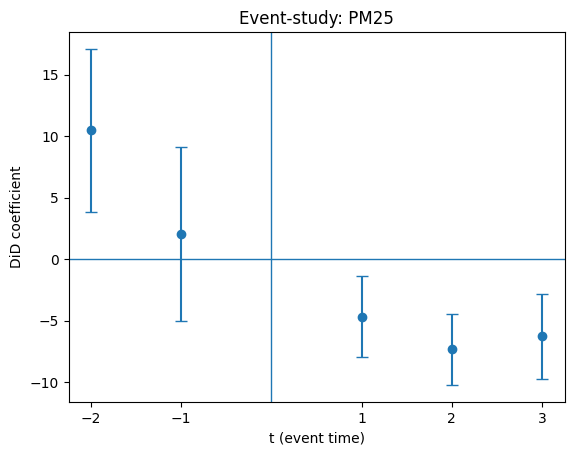


STAGE 4: PM10 ANALYSIS

RUNNING SINGLE STAGE OLS FOR: PM10
Intervention Date: 2018-12-31
Intervention falls in Period: P4
Dropping Reference Period (P0 equivalent): P3
Regression Formula: 
PM10 ~ D + P1 + P2 + P4 + P5 + P6 + P1:D + P2:D + P4:D + P5:D + P6:D

------------------------------
REGRESSION RESULTS
------------------------------
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.012
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     122.1
Date:                Wed, 26 Nov 2025   Prob (F-statistic):          1.53e-279
Time:                        15:38:03   Log-Likelihood:            -6.9500e+05
No. Observations:              107441   AIC:                         1.390e+06
Df Residuals:                  107429   BIC:                         1.390e+06
Df Model:                  

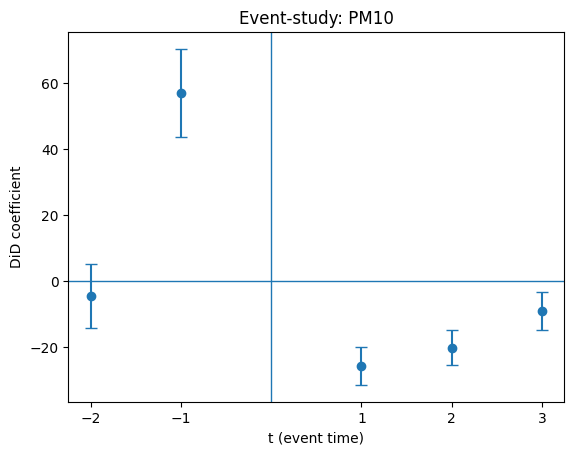

In [59]:
import pandas as pd
import datetime
# Assuming load_pollution_data and run_single_stage_ols are already defined in the notebook

# ==========================================
# CONFIGURATION FOR STAGE 4
# ==========================================

# 1. Define Groups
stage4_treated = [
    "Nehru Nagar", "JawaharLal Nehru Stadium", "Patparganj",
    "CRRI Mathura Road", "Lodhi Garden", "Sirifort",
    "Okhla Phase 2", "ITO", "Major Dhyan Chand National Stadium",
    "Sri Aurbindo Marg"
]

# Control Group (Same as before - Never Treated)
stage4_controlled = [
    "Najafgarh", "Narela", "Bawana", "Mundka", 
    "Rohini", "DTU", "Aya Nagar", "Dwarka Sector 8",
    "Dr. Karni Singh Shooting Range", "IGI Airport (T3)",
    "Mandir Marg", "NSIT Dwarka", "Alipur"
]

# 2. Define Parameters
INTERVENTION_DATE_S4 = datetime.datetime(2018, 12, 31)
YEARS_TO_LOAD = [2017, 2018, 2019]

# ==========================================
# EXECUTION
# ==========================================

# 1. Load Data
print("\nLOADING DATA FOR STAGE 4...")
df_s4 = load_pollution_data(PEAK_HOURS, stage4_treated, stage4_controlled, YEARS_TO_LOAD, base_path=BASE_PATH)

if df_s4 is not None:
    # 2. Prepare PM2.5 Data
    cols = ['TimeStamp', 'StationName', 'PM2.5', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm25_s4 = df_s4[cols].copy()
    
    # Clean PM2.5
    df_pm25_s4['PM2.5'] = pd.to_numeric(df_pm25_s4['PM2.5'], errors='coerce')
    df_pm25_s4 = df_pm25_s4.dropna(subset=['PM2.5'])
    df_pm25_s4 = df_pm25_s4.rename(columns={'PM2.5': 'PM25'})
    
    # Run OLS for PM2.5
    print("\n" + "="*30)
    print("STAGE 4: PM2.5 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm25_s4, 'PM25', YEARS_TO_LOAD, INTERVENTION_DATE_S4)
    
    # 3. Prepare PM10 Data
    cols = ['TimeStamp', 'StationName', 'PM10', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm10_s4 = df_s4[cols].copy()
    
    # Clean PM10
    df_pm10_s4['PM10'] = pd.to_numeric(df_pm10_s4['PM10'], errors='coerce')
    df_pm10_s4 = df_pm10_s4.dropna(subset=['PM10'])
    
    # Run OLS for PM10
    print("\n" + "="*30)
    print("STAGE 4: PM10 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm10_s4, 'PM10', YEARS_TO_LOAD, INTERVENTION_DATE_S4)

else:
    print("Failed to load data for Stage 4.")


LOADING DATA FOR STAGE 5...

PROCESSING DATA
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Patparganj                | 2928     | 69 (2.4%)              | 76 (2.6%)             
Patparganj                | 2920     | 101 (3.5%)             | 249 (8.5%)            
Patparganj                | 2920     | 83 (2.8%)              | 63 (2.2%)             
Najafgarh                 | 2928     | 314 (10.7%)            | 319 (10.9%)           
Najafgarh                 | 2920     | 158 (5.4%)             | 171 (5.9%)            
Najafgarh                 | 2920     | 210 (7.2%)             | 194 (6.6%)            
Narela                    | 2928     | 164 (5.6%)             | 197 (6.7%)            
Narela                    | 2920     | 92 (3.2%)              | 114 (3.9%)            
Narela                    | 2920     | 104 (3.6%)             | 85 (2.9%)             
Bawana                    | 2928     | 168 (5.7%)             | 101 (3.4%)          

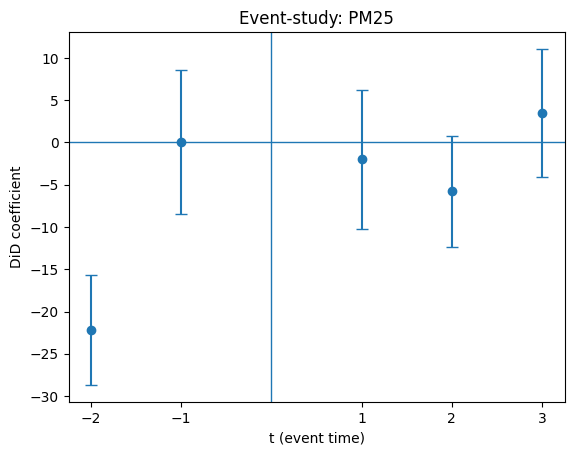


STAGE 5: PM10 ANALYSIS

RUNNING SINGLE STAGE OLS FOR: PM10
Intervention Date: 2021-08-06
Intervention falls in Period: P4
Dropping Reference Period (P0 equivalent): P3
Regression Formula: 
PM10 ~ D + P1 + P2 + P4 + P5 + P6 + P1:D + P2:D + P4:D + P5:D + P6:D

------------------------------
REGRESSION RESULTS
------------------------------
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     447.4
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        15:45:18   Log-Likelihood:            -6.8260e+05
No. Observations:              106907   AIC:                         1.365e+06
Df Residuals:                  106895   BIC:                         1.365e+06
Df Model:                  

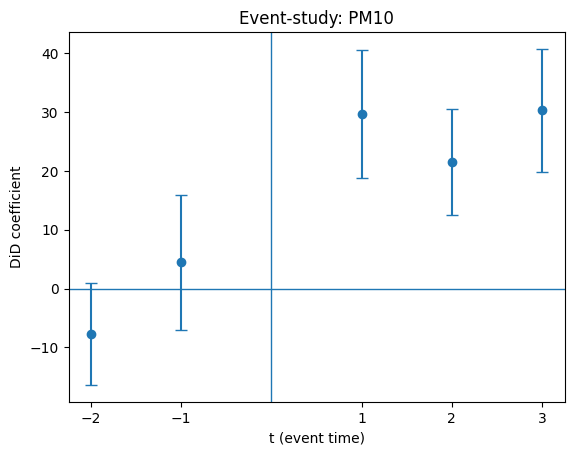

In [ ]:
# 1. Define Groups
# Stations closest to the gap completion (Trilokpuri - Mayur Vihar Pocket 1)
stage5_treated = [
    "Patparganj",
]

# Control Group (Same as before - Never Treated)
stage5_controlled = [
    "Najafgarh", "Narela", "Bawana", "Mundka", 
    "Rohini", "DTU", "Aya Nagar", "Dwarka Sector 8",
    "Dr. Karni Singh Shooting Range", "IGI Airport (T3)",
    "Mandir Marg", "NSIT Dwarka", "Alipur"
]

# 2. Define Parameters
INTERVENTION_DATE_S5 = datetime.datetime(2021, 8, 6)
# Loading 2019, 2020, 2021 to cover pre-periods and intervention year
YEARS_TO_LOAD = [2020, 2021, 2022]

# ==========================================
# EXECUTION
# ==========================================

# 1. Load Data
print("\nLOADING DATA FOR STAGE 5...")
df_s5 = load_pollution_data(PEAK_HOURS, stage5_treated, stage5_controlled, YEARS_TO_LOAD, base_path=BASE_PATH)

if df_s5 is not None:
    # 2. Prepare PM2.5 Data
    cols = ['TimeStamp', 'StationName', 'PM2.5', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm25_s5 = df_s5[cols].copy()
    
    # Clean PM2.5
    df_pm25_s5['PM2.5'] = pd.to_numeric(df_pm25_s5['PM2.5'], errors='coerce')
    df_pm25_s5 = df_pm25_s5.dropna(subset=['PM2.5'])
    df_pm25_s5 = df_pm25_s5.rename(columns={'PM2.5': 'PM25'})
    
    # Run OLS for PM2.5
    print("\n" + "="*30)
    print("STAGE 5: PM2.5 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm25_s5, 'PM25', YEARS_TO_LOAD, INTERVENTION_DATE_S5)
    
    # 3. Prepare PM10 Data
    cols = ['TimeStamp', 'StationName', 'PM10', 'D', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']
    df_pm10_s5 = df_s5[cols].copy()
    
    # Clean PM10
    df_pm10_s5['PM10'] = pd.to_numeric(df_pm10_s5['PM10'], errors='coerce')
    df_pm10_s5 = df_pm10_s5.dropna(subset=['PM10'])
    
    # Run OLS for PM10
    print("\n" + "="*30)
    print("STAGE 5: PM10 ANALYSIS")
    print("="*30)
    run_single_stage_ols(df_pm10_s5, 'PM10', YEARS_TO_LOAD, INTERVENTION_DATE_S5)

else:
    print("Failed to load data for Stage 5.")